# 04 - Leave one attack out

How well do the detectors catch an attack category excluded from model fitting and threshold calibration? For each held-out category:

- its rows are removed from the training and the validation part;
- the random forest is retrained without it, using the fixed hyperparameters from `02_supervised`;
- every model gets its threshold at 1% FPR on the validation part without that category;
- detection is measured on the distinct test rows of that category, with one row per feature vector in the category. FPR uses all normal test rows.

The hyperparameter search in `02_supervised` included all attack categories. This experiment measures the effect of holding out a category during random forest retraining and threshold calibration with those hyperparameters fixed.

Isolation Forest and the autoencoder are fitted on normal flows, which are the same in every round. Their configurations are fixed across rounds using the experiments in `03_anomaly`. Isolation Forest uses all normal training flows and all columns, and the autoencoder uses k=4. The validation comparisons in `03_anomaly` included all attack categories.

Held out: all nine attack categories in turn. Worms has only 44 distinct test rows, so every detection rate comes with a 95% Wilson interval. The interval assumes independent rows, which distinct rows are not (see METHODOLOGY.md), so the real uncertainty is larger.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, train_val_split, distinct_rows, FEATURES
from netad.preprocessing import build_preprocessor, TTL_COLUMNS
from netad.evaluation import FIGURES_DIR, REPORTS_DIR, RESULTS_PATH, choose_threshold, wilson_interval
from netad.models.autoencoder import train_autoencoder, reconstruction_error

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
test_cats = test_df["attack_cat"].to_numpy()
distinct = distinct_rows(test_df).to_numpy()

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
cat_tr = train_df.loc[X_tr.index, "attack_cat"].to_numpy()
cat_val = train_df.loc[X_val.index, "attack_cat"].to_numpy()

MAX_FPR = 0.01
HELD_OUT = ["Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"]
torch.manual_seed(42)

saved = {(r["model"], r["task"]): r for r in json.loads(RESULTS_PATH.read_text(encoding="utf-8"))}
rf_params = {k: v for k, v in saved[("RandomForest", "binary")]["params"].items() if k in RandomForestClassifier().get_params()}
rf_params

{'n_estimators': 800,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 20}

## Anomaly detectors

Trained once on the normal flows of the training part, which are the same whatever category is held out.

In [4]:
X_normal = X_tr[(y_tr == 0).to_numpy()]
X_val_normal = X_val[(y_val == 0).to_numpy()]

iforest = make_pipeline(
    build_preprocessor(),
    IsolationForest(n_estimators=300, max_samples=1.0, random_state=42, n_jobs=-1),
).fit(X_normal)

pre = build_preprocessor().fit(X_normal)
def to_ae(X):
    return np.asarray(pre.transform(X), dtype=np.float32)

ae, history = train_autoencoder(to_ae(X_normal), to_ae(X_val_normal), bottleneck=4, seed=42)

# library / function defaults, picked without looking at any data
iforest_default = make_pipeline(build_preprocessor(), IsolationForest(random_state=42, n_jobs=-1)).fit(X_normal)
ae_default, history_default = train_autoencoder(to_ae(X_normal), to_ae(X_val_normal), seed=42)

anomaly_models = {
    "IsolationForest": lambda X: -iforest.score_samples(X),
    "Autoencoder": lambda X: reconstruction_error(ae, to_ae(X)),
    "IsolationForest, default": lambda X: -iforest_default.score_samples(X),
    "Autoencoder, default": lambda X: reconstruction_error(ae_default, to_ae(X)),
}
anomaly_val = {name: score(X_val) for name, score in anomaly_models.items()}
anomaly_test = {name: score(X_test) for name, score in anomaly_models.items()}
len(history), len(history_default), ae_default.bottleneck

(358, 419, 8)

## Loop over held-out categories

For the random forest the held-out rows of test fall in two groups: rows whose feature vector is in the training part as another attack ("look-alikes", e.g. Analysis flows identical to Exploits flows), and the rest. Flagging a look-alike is recognising a known attack under another name, not detecting a new one.

Thresholds: the random forest uses the "fpr" mode like in `02`, the two anomaly detectors the "normal_quantile" mode like in `03`, which looks at normal validation flows only, so their threshold is the same in every round.

Sensitivity to the settings: every model is also run with library defaults, chosen without looking at any data: `RandomForestClassifier()` (100 trees, no depth limit), `IsolationForest()` (100 trees, `max_samples=256`) and the autoencoder with k=8, the default of `train_autoencoder`. If the held-out rates stay close, the hyperparameters picked with all categories present are not what explains them.

The random forest is also retrained without the three TTL columns. In training, sttl 31 is only normal traffic and attacks have 62 or 254, so an unseen attack could be flagged just for its TTL; if detection holds without them, TTL is not what catches it.

In [5]:
normal_test = test_cats == "Normal"
rows, test_scores = {}, {}
for cat in HELD_OUT:
    keep_tr, keep_val = cat_tr != cat, cat_val != cat
    rf = make_pipeline(
        build_preprocessor(), RandomForestClassifier(random_state=42, n_jobs=-1, **rf_params),
    ).fit(X_tr[keep_tr], y_tr[keep_tr])

    rf_no_ttl = make_pipeline(
        build_preprocessor(exclude=TTL_COLUMNS), RandomForestClassifier(random_state=42, n_jobs=-1, **rf_params),
    ).fit(X_tr[keep_tr], y_tr[keep_tr])

    rf_default = make_pipeline(
        build_preprocessor(), RandomForestClassifier(random_state=42, n_jobs=-1),
    ).fit(X_tr[keep_tr], y_tr[keep_tr])

    scores_val = {"RandomForest": rf.predict_proba(X_val[keep_val])[:, 1],
                  "RandomForest, no TTL": rf_no_ttl.predict_proba(X_val[keep_val])[:, 1],
                  "RandomForest, default": rf_default.predict_proba(X_val[keep_val])[:, 1],
                  **{name: s[keep_val] for name, s in anomaly_val.items()}}
    scores_test = {"RandomForest": rf.predict_proba(X_test)[:, 1],
                   "RandomForest, no TTL": rf_no_ttl.predict_proba(X_test)[:, 1],
                   "RandomForest, default": rf_default.predict_proba(X_test)[:, 1],
                   **anomaly_test}

    test_scores[cat] = scores_test
    target = distinct & (test_cats == cat)
    known_attacks = X_tr[keep_tr & (y_tr == 1).to_numpy()].drop_duplicates()
    lookalike = (test_df[FEATURES].merge(known_attacks.assign(_known=True), on=FEATURES, how="left")["_known"]
                 .notna().to_numpy())

    row = {
        "test rows": int(target.sum()),
        "sttl 254 share": (test_df["sttl"].to_numpy()[target] == 254).mean(),
        "RandomForest, seen": saved[("RandomForest", "binary")]["test_distinct"]["by_category"][cat]["flagged"],
    }
    for name in scores_val:
        mode = "normal_quantile" if name in anomaly_val else "fpr"
        threshold = choose_threshold(y_val[keep_val], scores_val[name], mode, max_fpr=MAX_FPR)
        flagged = scores_test[name] >= threshold
        row[name] = flagged[target].mean()
        row[f"{name} FPR"] = flagged[normal_test].mean()
        low, high = wilson_interval(int(flagged[target].sum()), int(target.sum()))
        row[f"{name} 95% CI"] = f"{low:.3f}-{high:.3f}"
        if name == "RandomForest":
            row["look-alike share"] = lookalike[target].mean()
            row["RandomForest on look-alikes"] = flagged[target & lookalike].mean() if (target & lookalike).any() else np.nan
            row["RandomForest on the rest"] = flagged[target & ~lookalike].mean() if (target & ~lookalike).any() else np.nan
    rows[cat] = row

loo = pd.DataFrame(rows).T
loo.to_csv(REPORTS_DIR / "leave_one_out.csv")
loo[["test rows", "RandomForest, seen", "RandomForest", "RandomForest, no TTL", "IsolationForest", "Autoencoder"]].round(3)

,test rows,"RandomForest, seen",RandomForest,"RandomForest, no TTL",IsolationForest,Autoencoder
Analysis,446,0.869955,0.867713,0.865471,0.82287,0.775785
Backdoor,346,0.979769,0.968208,0.956647,0.846821,0.823699
DoS,1718,0.919092,0.888824,0.869616,0.39057,0.376019
Exploits,7609,0.928243,0.758444,0.725588,0.174267,0.204626
Fuzzers,4838,0.303431,0.293923,0.273874,0.114717,0.121745
Generic,3657,0.97621,0.287394,0.270167,0.799836,0.800656
Reconnaissance,2703,0.954495,0.483167,0.470958,0.095819,0.09138
Shellcode,378,0.87037,0.783069,0.791005,0.0,0.005291
Worms,44,0.931818,0.931818,0.931818,0.159091,0.159091


For each held-out category, compare the random forest detection rates on exact training matches and on the remaining distinct attack flows. The FPR columns use all normal test flows. The random forest baseline with all categories included has 3.97% test FPR in `02`.

In [6]:
loo[["look-alike share", "RandomForest on look-alikes", "RandomForest on the rest",
     "RandomForest FPR", "RandomForest, no TTL FPR", "IsolationForest FPR", "Autoencoder FPR"]].round(3)

,look-alike share,RandomForest on look-alikes,RandomForest on the rest,RandomForest FPR,"RandomForest, no TTL FPR",IsolationForest FPR,Autoencoder FPR
Analysis,0.206278,1.0,0.833333,0.039784,0.042324,0.026378,0.031216
Backdoor,0.0,NaN,0.968208,0.042216,0.043162,0.026378,0.031216
DoS,0.112922,1.0,0.874672,0.041243,0.041324,0.026378,0.031216
Exploits,0.023393,1.0,0.752658,0.043297,0.044865,0.026378,0.031216
Fuzzers,0.031211,1.0,0.271176,0.030054,0.031973,0.026378,0.031216
Generic,0.005469,1.0,0.283475,0.043108,0.042378,0.026378,0.031216
Reconnaissance,0.063263,0.994152,0.448657,0.039514,0.043568,0.026378,0.031216
Shellcode,0.0,NaN,0.783069,0.039595,0.042595,0.026378,0.031216
Worms,0.0,NaN,0.931818,0.041946,0.043432,0.026378,0.031216


95% Wilson intervals for the held-out detection rates, and the share of each category's distinct test rows with sttl 254:

In [7]:
loo[["test rows", "sttl 254 share",
     "RandomForest", "RandomForest 95% CI", "IsolationForest", "IsolationForest 95% CI", "Autoencoder", "Autoencoder 95% CI"]].round(3)

,test rows,sttl 254 share,RandomForest,RandomForest 95% CI,IsolationForest,IsolationForest 95% CI,Autoencoder,Autoencoder 95% CI
Analysis,446,0.869955,0.867713,0.833-0.896,0.82287,0.785-0.856,0.775785,0.735-0.812
Backdoor,346,0.962428,0.968208,0.944-0.982,0.846821,0.805-0.881,0.823699,0.780-0.860
DoS,1718,0.664726,0.888824,0.873-0.903,0.39057,0.368-0.414,0.376019,0.353-0.399
Exploits,7609,0.407149,0.758444,0.749-0.768,0.174267,0.166-0.183,0.204626,0.196-0.214
Fuzzers,4838,0.997106,0.293923,0.281-0.307,0.114717,0.106-0.124,0.121745,0.113-0.131
Generic,3657,0.937927,0.287394,0.273-0.302,0.799836,0.787-0.812,0.800656,0.787-0.813
Reconnaissance,2703,0.99778,0.483167,0.464-0.502,0.095819,0.085-0.107,0.09138,0.081-0.103
Shellcode,378,1.0,0.783069,0.739-0.822,0.0,0.000-0.010,0.005291,0.001-0.019
Worms,44,1.0,0.931818,0.818-0.977,0.159091,0.079-0.294,0.159091,0.079-0.294


Tuned settings next to the library defaults, held-out detection and test FPR:

In [8]:
pairs = ["RandomForest", "IsolationForest", "Autoencoder"]
pd.concat({
    "held-out detection": loo[[c for p in pairs for c in (p, f"{p}, default")]],
    "test FPR": loo[[f"{c} FPR" for p in pairs for c in (p, f"{p}, default")]].rename(columns=lambda c: c.removesuffix(" FPR")),
}, axis=1).round(3)

held-out detection                                        \
                     RandomForest RandomForest, default IsolationForest   
Analysis                 0.867713              0.865471         0.82287   
Backdoor                 0.968208              0.950867        0.846821   
DoS                      0.888824              0.875437         0.39057   
Exploits                 0.758444              0.724537        0.174267   
Fuzzers                  0.293923              0.302604        0.114717   
Generic                  0.287394              0.329232        0.799836   
Reconnaissance           0.483167              0.469848        0.095819   
Shellcode                0.783069              0.761905             0.0   
Worms                    0.931818              0.909091        0.159091   

                                                                          \
               IsolationForest, default Autoencoder Autoencoder, default   
Analysis                            0.0    0.775785             0.060538   
Backdoor                            0.0    0.823699             0.127168   
DoS                                 0.0    0.376019             0.203143   
Exploits                            0.0    0.204626             0.309633   
Fuzzers                        0.000207    0.121745             0.051054   
Generic                        0.006016    0.800656             0.565764   
Reconnaissance                      0.0     0.09138             0.038476   
Shellcode                           0.0    0.005291             0.013228   
Worms                               0.0    0.159091             0.159091   

                   test FPR                                        \
               RandomForest RandomForest, default IsolationForest   
Analysis           0.039784              0.046189        0.026378   
Backdoor           0.042216              0.046486        0.026378   
DoS                0.041243              0.047784        0.026378   
Exploits           0.043297              0.048865        0.026378   
Fuzzers            0.030054              0.030351        0.026378   
Generic            0.043108              0.049486        0.026378   
Reconnaissance     0.039514              0.046595        0.026378   
Shellcode          0.039595              0.046892        0.026378   
Worms              0.041946              0.047703        0.026378   

                                                                          
               IsolationForest, default Autoencoder Autoencoder, default  
Analysis                       0.029351    0.031216             0.031297  
Backdoor                       0.029351    0.031216             0.031297  
DoS                            0.029351    0.031216             0.031297  
Exploits                       0.029351    0.031216             0.031297  
Fuzzers                        0.029351    0.031216             0.031297  
Generic                        0.029351    0.031216             0.031297  
Reconnaissance                 0.029351    0.031216             0.031297  
Shellcode                      0.029351    0.031216             0.031297  
Worms                          0.029351    0.031216             0.031297

## Detection at the same test FPR (diagnostic)

With validation thresholds the models sit at different FPRs on test (2.6% for Isolation Forest, 3.1% for the autoencoder, 4.0-4.5% for the random forest). Here each model gets the threshold that gives the same FPR on the normal test flows, and detection of the held-out category is read on its distinct test rows. These thresholds are picked on test and can't be used in practice: this separates ranking quality from calibration, it doesn't replace the table above.

In [9]:
y_test_bin = (test_cats != "Normal").astype(int)
models = ["RandomForest", "IsolationForest", "Autoencoder"]


def detection_at_fpr(scores, target, fpr):
    threshold = choose_threshold(y_test_bin, scores, "normal_quantile", max_fpr=fpr)
    return (scores[target] >= threshold).mean()


at_fpr = pd.DataFrame({
    (f"{f:.0%} FPR", name): {
        cat: detection_at_fpr(test_scores[cat][name], distinct & (test_cats == cat), f) for cat in HELD_OUT
    }
    for f in [0.01, 0.02, 0.05]
    for name in models
})
at_fpr.round(3)

1% FPR                                   2% FPR  \
               RandomForest IsolationForest Autoencoder RandomForest   
Analysis              0.778           0.253       0.455        0.850   
Backdoor              0.809           0.353       0.572        0.899   
DoS                   0.752           0.150       0.204        0.830   
Exploits              0.549           0.047       0.080        0.635   
Fuzzers               0.113           0.044       0.066        0.173   
Generic               0.136           0.412       0.775        0.178   
Reconnaissance        0.345           0.025       0.035        0.388   
Shellcode             0.566           0.000       0.000        0.664   
Worms                 0.841           0.114       0.136        0.886   

                                                 5% FPR                  \
               IsolationForest Autoencoder RandomForest IsolationForest   
Analysis                 0.688       0.769        0.868           0.872   
Backdoor                 0.783       0.809        0.977           0.858   
DoS                      0.321       0.335        0.903           0.487   
Exploits                 0.126       0.142        0.780           0.372   
Fuzzers                  0.096       0.111        0.393           0.135   
Generic                  0.716       0.789        0.322           0.875   
Reconnaissance           0.070       0.077        0.528           0.112   
Shellcode                0.000       0.000        0.825           0.003   
Worms                    0.159       0.159        0.932           0.159   

                            
               Autoencoder  
Analysis             0.787  
Backdoor             0.847  
DoS                  0.429  
Exploits             0.330  
Fuzzers              0.137  
Generic              0.843  
Reconnaissance       0.142  
Shellcode            0.008  
Worms                0.227

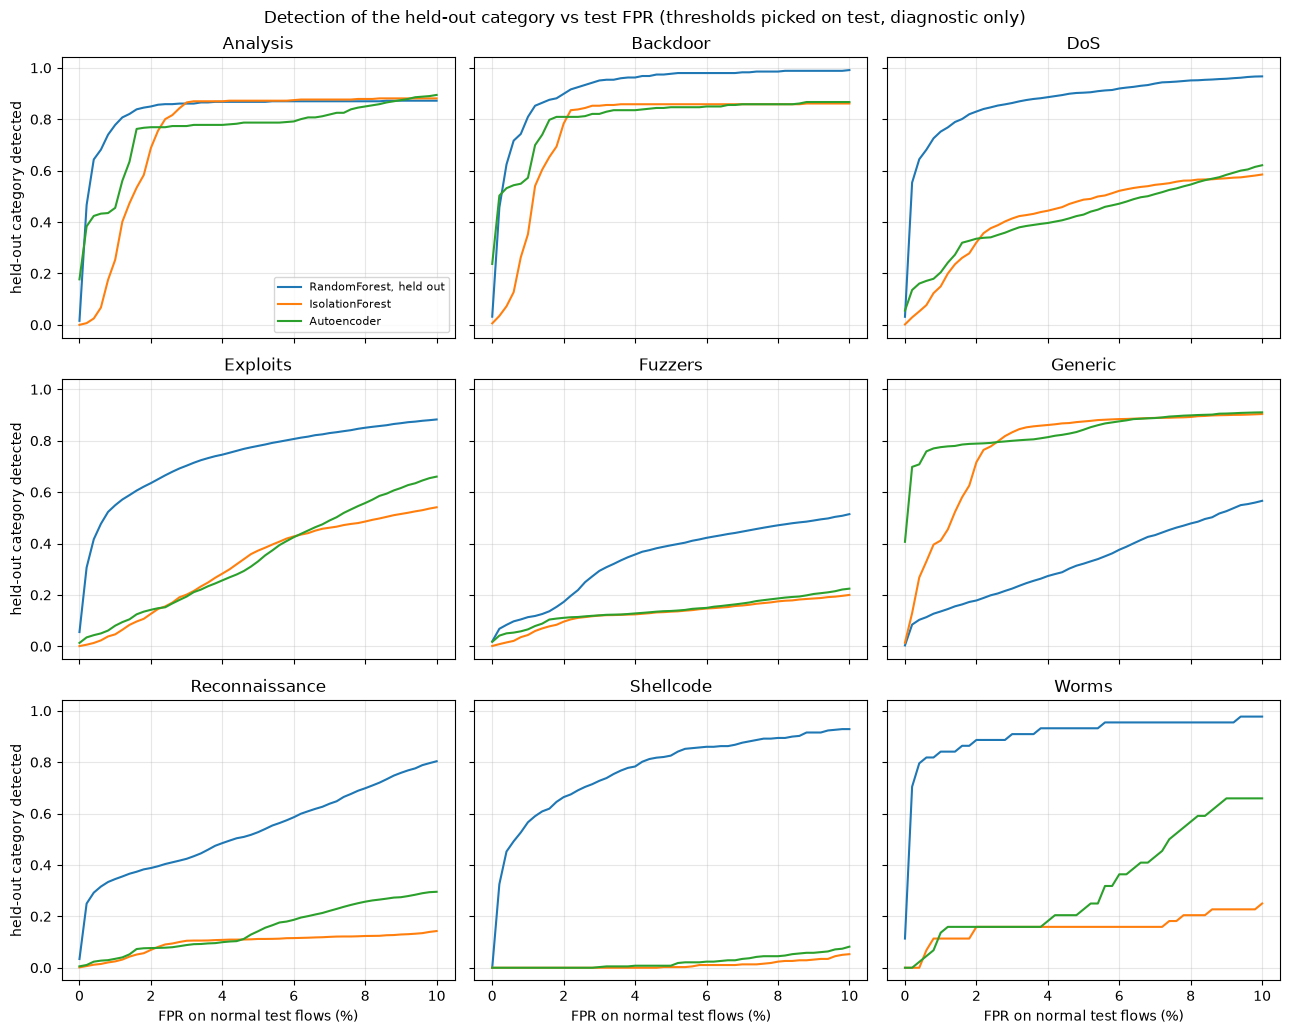

In [10]:
grid = np.arange(0, 0.1001, 0.002)
fig, axes = plt.subplots(3, 3, figsize=(13, 10.5), sharex=True, sharey=True)
for ax, cat in zip(axes.flat, HELD_OUT):
    target = distinct & (test_cats == cat)
    for name in models:
        label = "RandomForest, held out" if name == "RandomForest" else name
        ax.plot(grid * 100, [detection_at_fpr(test_scores[cat][name], target, f) for f in grid], label=label)
    ax.set_title(cat)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("FPR on normal test flows (%)")
for ax in axes[:, 0]:
    ax.set_ylabel("held-out category detected")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Detection of the held-out category vs test FPR (thresholds picked on test, diagnostic only)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "leave_one_out_curves.png", dpi=120)
plt.show()

## Seed variation

Everything above uses seed 42. Here the whole round is repeated with seeds 1 and 2: a new train / validation split, a new random forest per held-out category, new Isolation Forest and autoencoder fits and new thresholds, same settings. Seed 42 is taken from the table above. The spread shows how much of each number is the luck of one split and one fit.

In [11]:
def seed_round(seed):
    """Held-out detection and test FPR of the three main models, everything refit with `seed`."""
    Xs_tr, Xs_val, ys_tr, ys_val = train_val_split(train_df, "label", seed=seed)
    cs_tr = train_df.loc[Xs_tr.index, "attack_cat"].to_numpy()
    cs_val = train_df.loc[Xs_val.index, "attack_cat"].to_numpy()
    normal_tr, normal_val = Xs_tr[(ys_tr == 0).to_numpy()], Xs_val[(ys_val == 0).to_numpy()]

    if_s = make_pipeline(
        build_preprocessor(), IsolationForest(n_estimators=300, max_samples=1.0, random_state=seed, n_jobs=-1),
    ).fit(normal_tr)
    pre_s = build_preprocessor().fit(normal_tr)
    to_s = lambda X: np.asarray(pre_s.transform(X), dtype=np.float32)
    ae_s, _ = train_autoencoder(to_s(normal_tr), to_s(normal_val), bottleneck=4, seed=seed)
    val_scores = {"IsolationForest": -if_s.score_samples(Xs_val), "Autoencoder": reconstruction_error(ae_s, to_s(Xs_val))}
    test_s = {"IsolationForest": -if_s.score_samples(X_test), "Autoencoder": reconstruction_error(ae_s, to_s(X_test))}

    out = {}
    for cat in HELD_OUT:
        keep_tr, keep_val = cs_tr != cat, cs_val != cat
        rf_s = make_pipeline(
            build_preprocessor(), RandomForestClassifier(random_state=seed, n_jobs=-1, **rf_params),
        ).fit(Xs_tr[keep_tr], ys_tr[keep_tr])
        sv = {"RandomForest": rf_s.predict_proba(Xs_val[keep_val])[:, 1], **{n: s[keep_val] for n, s in val_scores.items()}}
        st = {"RandomForest": rf_s.predict_proba(X_test)[:, 1], **test_s}
        target = distinct & (test_cats == cat)
        for name in sv:
            mode = "fpr" if name == "RandomForest" else "normal_quantile"
            flagged = st[name] >= choose_threshold(ys_val[keep_val], sv[name], mode, max_fpr=MAX_FPR)
            out[(cat, name)] = {"detection": flagged[target].mean(), "test FPR": flagged[normal_test].mean()}
    return out


by_seed = {42: {(cat, name): {"detection": float(loo.loc[cat, name]), "test FPR": float(loo.loc[cat, f"{name} FPR"])}
                for cat in HELD_OUT for name in models}}
for seed in [1, 2]:
    by_seed[seed] = seed_round(seed)

seeds = pd.concat({seed: pd.DataFrame(r).T for seed, r in by_seed.items()}, names=["seed", "category", "model"])
seeds.to_csv(REPORTS_DIR / "leave_one_out_seeds.csv")

In [12]:
detection = seeds["detection"].unstack("seed")
spread = {}
for name in models:
    d = detection.xs(name, level="model")
    spread[name] = pd.DataFrame({"seed 42": d[42], "min": d.min(axis=1), "max": d.max(axis=1),
                                 "range": d.max(axis=1) - d.min(axis=1)})
pd.concat(spread, axis=1).round(3)

RandomForest                      IsolationForest         \
                    seed 42    min    max  range         seed 42    min   
category                                                                  
Analysis              0.868  0.868  0.870  0.002           0.823  0.789   
Backdoor              0.968  0.960  0.968  0.009           0.847  0.841   
DoS                   0.889  0.889  0.895  0.006           0.391  0.381   
Exploits              0.758  0.758  0.776  0.017           0.174  0.159   
Fuzzers               0.294  0.294  0.339  0.045           0.115  0.110   
Generic               0.287  0.287  0.351  0.063           0.800  0.800   
Reconnaissance        0.483  0.459  0.491  0.033           0.096  0.089   
Shellcode             0.783  0.783  0.810  0.026           0.000  0.000   
Worms                 0.932  0.932  0.955  0.023           0.159  0.159   

                             Autoencoder                       
                  max  range     seed 42    min    max  range  
category                                                       
Analysis        0.823  0.034       0.776  0.464  0.776  0.312  
Backdoor        0.847  0.006       0.824  0.653  0.824  0.171  
DoS             0.391  0.010       0.376  0.300  0.376  0.076  
Exploits        0.179  0.020       0.205  0.205  0.314  0.109  
Fuzzers         0.115  0.005       0.122  0.081  0.122  0.041  
Generic         0.844  0.045       0.801  0.801  0.871  0.071  
Reconnaissance  0.096  0.007       0.091  0.044  0.091  0.047  
Shellcode       0.000  0.000       0.005  0.003  0.005  0.003  
Worms           0.159  0.000       0.159  0.159  0.182  0.023

Test FPR for each seed, lowest and highest over the nine rounds (the anomaly detectors' threshold doesn't depend on the round):

In [13]:
seeds["test FPR"].unstack("seed").groupby(level="model").agg(["min", "max"]).round(4)

seed                 42              1               2         
                    min     max     min     max     min     max
model                                                          
Autoencoder      0.0312  0.0312  0.0372  0.0372  0.0333  0.0333
IsolationForest  0.0264  0.0264  0.0262  0.0262  0.0267  0.0267
RandomForest     0.0301  0.0433  0.0412  0.0479  0.0354  0.0471

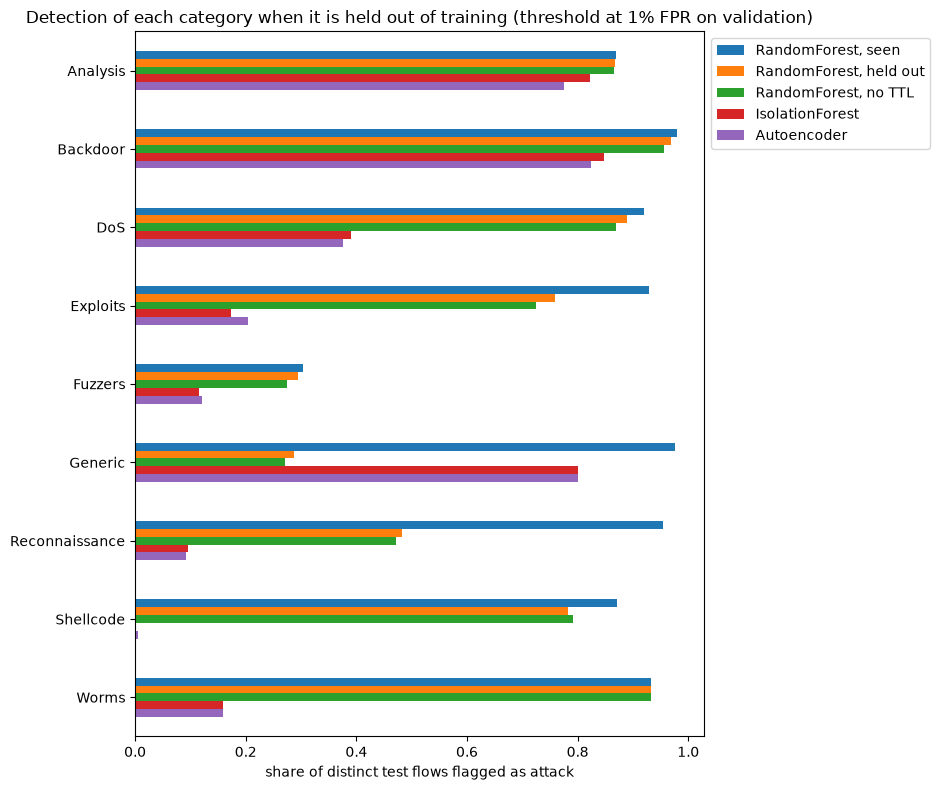

In [14]:
ax = loo[["RandomForest, seen", "RandomForest", "RandomForest, no TTL", "IsolationForest", "Autoencoder"]].rename(
    columns={"RandomForest": "RandomForest, held out"}
).plot.barh(figsize=(9.5, 8))
ax.invert_yaxis()
ax.set_xlabel("share of distinct test flows flagged as attack")
ax.set_title("Detection of each category when it is held out of training (threshold at 1% FPR on validation)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "leave_one_out.png", dpi=120)
plt.show()

## Conclusions

1. **Generic is the case for anomaly detection, with the tuned settings.** Held out of training, the random forest catches 29% of the distinct Generic test flows (98% when it has seen them, 33% with default settings). Isolation Forest and the autoencoder catch 80%, at a lower test FPR (2.6% and 3.1% against 4.3%). At the same test FPR the gap stays: 41-78% against 14% at 1% FPR, 84-88% against 32% at 5%. It also holds over three seeds: 29-35% for the forest, 80-84% for Isolation Forest, 80-87% for the autoencoder.
2. **For most categories the supervised model still wins without having seen them.** Held out, the random forest catches 97% of Backdoor, 93% of Worms, 89% of DoS, 87% of Analysis, 78% of Shellcode and 76% of Exploits; the anomaly detectors 0-85% on the same categories. Exact look-alikes (the same feature vector in training as another attack) are a small part of it: 21% of Analysis, 11% of DoS, none of Backdoor, Shellcode or Worms. On the other rows the forest still catches 75-97%.
3. **Fuzzers and Reconnaissance are missed by every model when unseen.** The forest catches 29% and 48%, the anomaly detectors under 13%. Fuzzers is barely caught even when seen (30%). Without it in training the forest's test FPR drops from about 4.0% to 3.0%: the Fuzzers flows that look like normal traffic were pulling the boundary into normal traffic.
4. **Shellcode is caught by the forest and invisible to the anomaly detectors.** 78% held out (87% seen, 79% without TTL), 0-0.5% for Isolation Forest and the autoencoder. All its distinct test rows have sttl 254, but so do 99.7% of Fuzzers and 99.8% of Reconnaissance rows, which the forest mostly misses: sharing the attackers' sttl is not enough for an unseen category to be detected.
5. **Worms has too few rows for a firm number.** On 44 distinct test rows the forest catches 93% (95% Wilson interval 82-98%), the anomaly detectors 16% (8-29%). The rows are not independent, so the real intervals are wider.
6. **The anomaly detector results depend on their settings, the forest's do not.** With library defaults the forest moves by at most 4.2 points on any category (Generic 29% -> 33%, Exploits 76% -> 72%). Isolation Forest with the default `max_samples=256` catches under 1% of every category (its validation pAUC in `03` was 0.50), and the autoencoder with k=8 changes a lot per category (Analysis 78% -> 6%, Generic 80% -> 57%, Exploits 20% -> 31%). The Generic result holds for the autoencoder at k=8 but not for the default Isolation Forest. Below 1% FPR the anomaly detectors rank attacks close to chance, so which flows end up above the threshold is fragile.
7. **TTL is not what catches the unseen attacks.** Retrained without `sttl`, `dttl` and `ct_state_ttl`, the random forest loses at most 3.3 points on a held-out category (Exploits 75.8% -> 72.6%, Fuzzers 29.4% -> 27.4%, Generic 28.7% -> 27.0%), Shellcode goes up slightly (78.3% -> 79.1%) and Worms doesn't move. The same information can still come from other columns, so this does not show that the model learned attack behaviour (the limit already noted in `02`).
8. **At the same test FPR (diagnostic) the picture holds.** With thresholds picked on test for equal FPR the forest is ahead on every category except Generic, and on Analysis from about 3% FPR, where Isolation Forest matches it (87% at 5%). Curves in `reports/figures/leave_one_out_curves.png`.
9. **Over three seeds the forest and Isolation Forest are stable, the autoencoder is not.** With a new train / validation split and new fits for seeds 1 and 2, the forest's held-out detection moves by at most 6 points (Generic 29-35%, Fuzzers 29-34%) and Isolation Forest's by at most 4.5 points. The autoencoder moves a lot: Analysis 46-78%, Backdoor 65-82%, Exploits 21-31%, and its test FPR 3.1-3.7%. Seed 42 happens to be its best run on Analysis, Backdoor and DoS, so its single-seed numbers above are on the optimistic side there. Together with point 6: Isolation Forest is sensitive to its settings but not to the seed, the autoencoder to both.
10. **Limits.** This is an exploratory held-out-category analysis, not evidence of zero-day detection. The hyperparameters and anomaly detector settings were chosen with every category present, only the training and threshold exclude the held-out one, and all categories come from the same attack tool and hosts, so a held-out category still shares traffic characteristics with the ones the model was trained on. The main models are run with three seeds; the default-settings and no-TTL variants with one. Under a 1% validation FPR budget the test FPR over the three seeds is 3.0-4.8% for the random forest, 2.6-2.7% for Isolation Forest and 3.1-3.7% for the autoencoder (the anomaly detectors' threshold comes from normal validation flows only and is the same in every round of a seed).